# Silero VAD
Quick look at one file and where the speech is. Silero needs 16 kHz.

In [13]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
import torch
import torchaudio
from IPython.display import Audio, display

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
wavs = sorted((root / "data" / "raw_audios").glob("*.wav"))
for i, p in enumerate(wavs):
    print(i, p.name)

0 abuser.wav


In [14]:
audio_path = wavs[0]
SR = 16000

audio, sr = sf.read(audio_path, dtype="float32", always_2d=True)
wav = torch.from_numpy(audio.T.copy()).mean(dim=0)
wav = torchaudio.functional.resample(wav, sr, SR)
print(f"{audio_path.name}: {len(wav) / SR:.1f}s")
display(Audio(wav[: 60 * SR].numpy(), rate=SR))  # first minute only

abuser.wav: 69.2s


In [15]:
model, utils = torch.hub.load("snakers4/silero-vad", "silero_vad", trust_repo=True)
get_speech_timestamps = utils[0]

speech = get_speech_timestamps(wav, model, sampling_rate=SR, return_seconds=True)
print(len(speech), "segments,", round(sum(s["end"] - s["start"] for s in speech), 1), "s speech")

Using cache found in /Users/macbook/.cache/torch/hub/snakers4_silero-vad_master


13 segments, 63.9 s speech


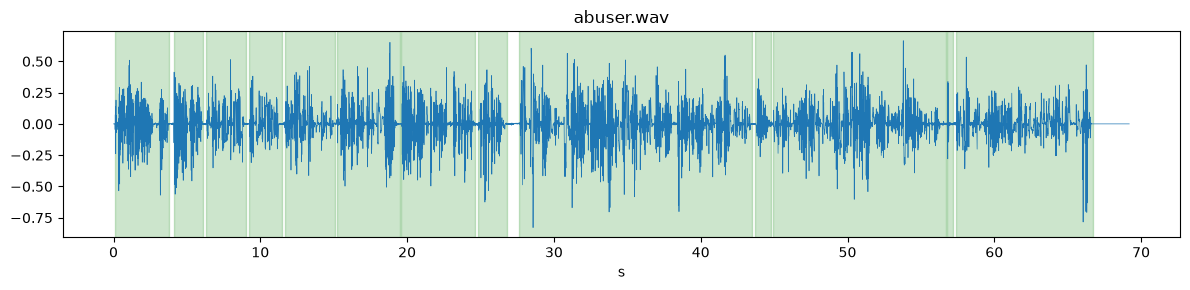

In [16]:
step = SR // 100
t = np.arange(0, len(wav), step) / SR
plt.figure(figsize=(12, 3))
plt.plot(t, wav[::step].numpy(), linewidth=0.5)
for s in speech:
    plt.axvspan(s["start"], s["end"], color="green", alpha=0.2)
plt.xlabel("s")
plt.title(audio_path.name)
plt.tight_layout()
plt.show()